# Inversión de forma de onda completa: cycle-skipping y controles negativos

**Pregunta:** ¿Los estados FWI multiescala guardados mejoran ondas de entrenamiento y retención, y qué falla en el control de salto de ciclo?
**Nivel 3 — Experimento de investigación** · 60–90 min · propagación de ondas y optimización

## Objetivos
- Leer objetivo acústico Deepwave, parametrización, continuación y evaluación reales del producto.
- Recorrer estados registrados para examinar el efecto de iteraciones.
- Comparar dos valores de regularización con observaciones sintéticas idénticas.
- Inspeccionar el desafío de cycle-skipping, incluido residual retenido de forma de onda.

## Preparación

Ejecute desde la raíz en el entorno fijado:
pip install numpy==2.2.6 scipy==1.15.2 matplotlib==3.10.8

La celda experimental imprime las versiones activas.

## Datos
Son artefactos sintéticos **generados por Deepwave** y comprometidos. Los experimentos de iteración y regularización reproducen estados guardados; no inician un solve GPU. El desafío cycle-skipping permanece como control negativo. No son datos de terreno ni prueban que FWI funcione con cualquier entrada.

## Método

La implementación data-pipeline/seismic.py resuelve ecuación acústica escalar 2D con Deepwave, deriva automáticamente el objetivo waveform y actualiza velocidad acotada con L-BFGS y búsqueda fuerte de Wolfe. Usa cuatro mallas de control progresivas y penalización de gradiente físico. El objetivo guardado es aproximadamente

Φ(m)=||P_A B_f(F(m)−d)||²₂ / ||P_A B_f d||²₂ + βR(m)

donde F(m) es el gather simulado, d la observación sintética, P_A selecciona receptores de entrenamiento y B_f es el filtro de fase cero de la etapa de continuación. Los receptores i mod 5 = 2 quedan fuera del objetivo y selección de estados. Puntajes retenidos son diagnósticos posteriores.

Hay cycle-skipping cuando las oscilaciones predichas y observadas están suficientemente desfasadas para que gradientes locales favorezcan alineación/modelo erróneos; más iteraciones no garantizan salir. La continuación de frecuencia puede ampliar la cuenca de atracción, pero el caso desafiado permanece como control negativo. La inspección de estados se guía por historial de entrenamiento; trazas retenidas son diagnóstico únicamente.

La comparación beta usa dos artefactos del mismo modelo estratificado sintético, adquisición, semilla y ruido (β=0.001 frente a β=0.03). El notebook verifica observaciones idénticas. El desafío salino tiene geometría diferente y fuente de 9 Hz: ilustra fallo y no es experimento beta emparejado.

## Estado del arte

Cycle-skipping es una no convexidad central de la inversión waveform. Continuación en frecuencia, parametrización multiescala y regularización pueden mejorar el condicionamiento, pero el éxito depende de banda fuente, modelo inicial, adquisición y ruido. El desafío salino permanece porque la continuación no garantiza recuperación.

### Preguntas
1. ¿Disminuye monótonamente el misfit de entrenamiento? ¿Le sigue el misfit retenido?
2. ¿Qué estructura cambia al subir β: detalle respaldado por datos o suavidad impuesta por el prior?
3. ¿Cumple el desafío salino el criterio declarado? ¿Por qué conservar el control negativo?


### Experimento 3 — seleccione iteración registrada y caso de regularización

Ajuste METHOD y STATE_INDEX para inspeccionar la trayectoria guardada. Las cuatro etapas tienen 28 actualizaciones del optimizador más el estado inicial sin actualizar. La inspección usa solo historial de entrenamiento. BETA_CASE selecciona una de las corridas estratificadas con misma entrada.

In [1]:
from importlib.metadata import version

print("Versiones del entorno:", {name: version(name) for name in ["numpy", "scipy", "matplotlib"]})
# Celda de experimento reproducible del notebook.
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

root = next(
    p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data").is_dir() and (p / "data-pipeline").is_dir()
)
data = root / "data/derived/v2"


def load_case(case_id, variant="reference"):
    return json.loads((data / case_id / f"{variant}.json").read_text(encoding="utf-8"))


layered = load_case("FWI_LAYERED", "reference")
strong = load_case("FWI_LAYERED", "regularization")
challenge = load_case("FWI_CYCLE_SKIP", "reference")
assert layered["observed"] == strong["observed"], "beta comparison must use identical observations"
METHOD = "fwi-multiscale"  # also inspect fwi-l2
STATE_INDEX = 80  # rango 0..115 in stored multistage history
BETA_CASE = "reference"  # beta de referencia=.001; beta de regularización=.03
chosen_case = layered if BETA_CASE == "reference" else strong
records = chosen_case["methods"][METHOD]["history_records"]
assert 0 <= STATE_INDEX < len(records)


Versiones del entorno: {'numpy': '2.2.6', 'scipy': '1.15.2', 'matplotlib': '3.10.8'}


### El índice de estado 80 selecciona una entrada registrada del historial FWI con su fase, actualización, malla de control, frecuencia de corte y objetivo. Estos valores reproducen una ejecución guardada; en esta lección no se resuelve la ecuación de onda. Los errores relativos de entrenamiento y de datos retenidos pertenecen a ese estado guardado y deben leerse junto con el origen sintético del artefacto.

In [2]:
# Selecciona el experimento estratificado con semilla e informa su procedencia.
selected = records[STATE_INDEX]
print("Motor:", layered["engine"])
print("Origen sintético:", layered["parameters"]["data_origin"], "| estados guardados:", len(records))
print("Valores de beta:", layered["parameters"]["regularization"], strong["parameters"]["regularization"])
print("Observaciones estratificadas idénticas:", layered["observed"] == strong["observed"])
print(
    "Estado seleccionado:",
    {
        k: selected[k]
        for k in (
            "phase",
            "update",
            "control_grid",
            "cutoff_hz",
            "objective",
            "active_relative_mse",
            "withheld_relative_mse",
        )
    },
)
print("Solo reproducción del artefacto: no se ejecutó el solve.")


Motor: Deepwave 0.0.27 / PyTorch automatic differentiation
Origen sintético: same-operator synthetic pressure, independent additive Gaussian noise | estados guardados: 116
Valores de beta: 0.001 0.03
Observaciones estratificadas idénticas: True
Estado seleccionado: {'phase': 'spatial-2', 'update': 22, 'control_grid': [17, 24], 'cutoff_hz': 8.0, 'objective': 0.0001239068661, 'active_relative_mse': 0.00114877522, 'withheld_relative_mse': 0.001611977699}
Solo reproducción del artefacto: no se ejecutó el solve.


### La tabla compara dos intensidades de regularización sobre las mismas observaciones estratificadas e incluye el caso de salto de ciclo. Las trayectorias conservan las 116 actualizaciones registradas, de modo que es posible comparar el objetivo con los errores de entrenamiento y de datos retenidos en vez de seleccionar una imagen de modelo visualmente atractiva. Esta comparación reproduce resultados guardados; no es un nuevo barrido de parámetros.

In [3]:
# Reúne trayectorias registradas del modelo para comparar regularización.
trajectories = {
    f"beta={layered['parameters']['regularization']:g}": layered["methods"][METHOD]["history_records"],
    f"beta={strong['parameters']['regularization']:g}": strong["methods"][METHOD]["history_records"],
}
display(
    pd.DataFrame(
        [
            {
                'case': case["id"],
                "method": METHOD,
                "beta": case["methods"][METHOD]["solver"]["beta"],
                "model_RMSE_ratio": case["methods"][METHOD]["metrics"]["model_rmse_ratio"],
                "active_WRMS": case["methods"][METHOD]["metrics"]["active_wrms"],
                "withheld_WRMS": case["methods"][METHOD]["metrics"]["withheld_wrms"],
                "verdict": case["methods"][METHOD]["evaluation"]["status"],
            }
            for case in (layered, strong, challenge)
        ]
    ).round(4)
)
print("Códigos de motivo del caso de desafío:", challenge["methods"][METHOD]["evaluation"]["reason_codes"])

import sys

sys.path.insert(0, str(root / "data-pipeline"))


,case,method,beta,model_RMSE_ratio,active_WRMS,withheld_WRMS,verdict
0,FWI_LAYERED,fwi-multiscale,0.001,0.5269,1.2078,1.2330,recovered
1,FWI_LAYERED,fwi-multiscale,0.030,1.7380,2.4982,2.5564,failed
2,FWI_CYCLE_SKIP,fwi-multiscale,0.001,0.8026,1.7506,1.9659,negative-control


Códigos de motivo del caso de desafío: ['salt_cycle_skipping_challenge']


### Diagnóstico 2 — trayectoria, efecto del modelo y control negativo

Los gráficos usan estados guardados del solver. Los paneles comparan velocidad final de corridas beta emparejadas y desafío cycle-skipping separado. Se muestra un receptor retenido durante el ajuste como contexto; no selecciona iteración ni ajusta beta.

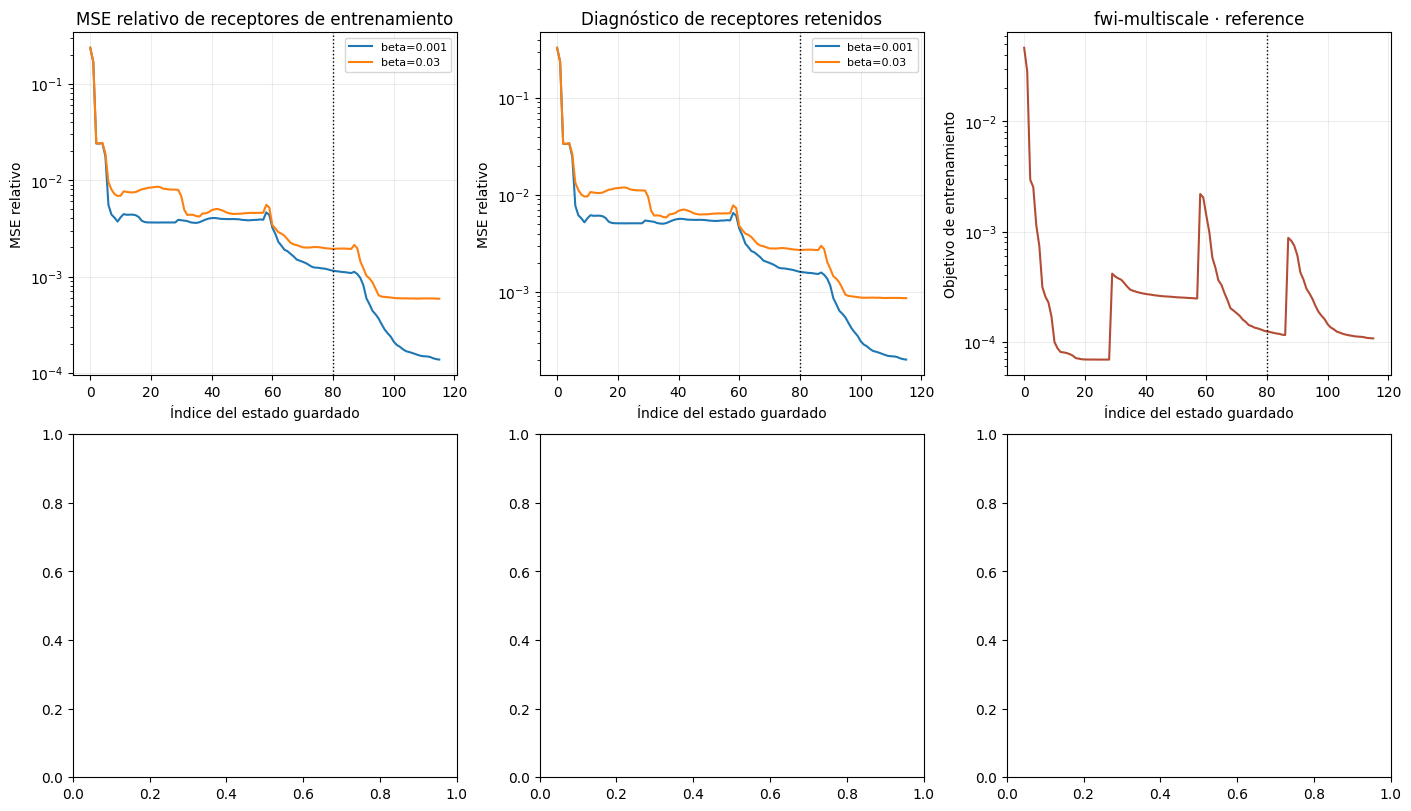

In [4]:
# Grafica la evolución registrada del objetivo, modelo, residual y diagnóstico de paso.
fig, axes = plt.subplots(2, 3, figsize=(14, 8), constrained_layout=True)
for label, rows in trajectories.items():
    x = np.arange(len(rows))
    axes[0, 0].plot(x, [r["active_relative_mse"] for r in rows], label=label)
    axes[0, 1].plot(x, [r["withheld_relative_mse"] for r in rows], label=label)
for ax, title in zip(
    axes[0, :2], ["MSE relativo de receptores de entrenamiento", "Diagnóstico de receptores retenidos"]
):
    ax.axvline(STATE_INDEX, color="black", ls=":", lw=1)
    ax.set(xlabel="Índice del estado guardado", ylabel="MSE relativo", title=title)
    ax.set_yscale("log")
    ax.grid(alpha=0.22)
    ax.legend(fontsize=8)
axes[0, 2].plot(np.arange(len(records)), [r['objective'] for r in records], color="#b34c34")
axes[0, 2].axvline(STATE_INDEX, color="black", ls=":", lw=1)
axes[0, 2].set(
    xlabel="Índice del estado guardado", ylabel="Objetivo de entrenamiento", title=f"{METHOD} · {BETA_CASE}"
)
axes[0, 2].set_yscale("log")
axes[0, 2].grid(alpha=0.22)


### Los tres paneles muestran modelos de velocidad guardados para la penalización de referencia, una penalización mayor y el control de salto de ciclo. Los ejes comunes de distancia y profundidad permiten comparar la geometría, pero el color y la suavidad no demuestran ajuste a los datos. Lea cada imagen junto con su objetivo y error retenido; el caso de sal se conserva intencionalmente como control negativo.

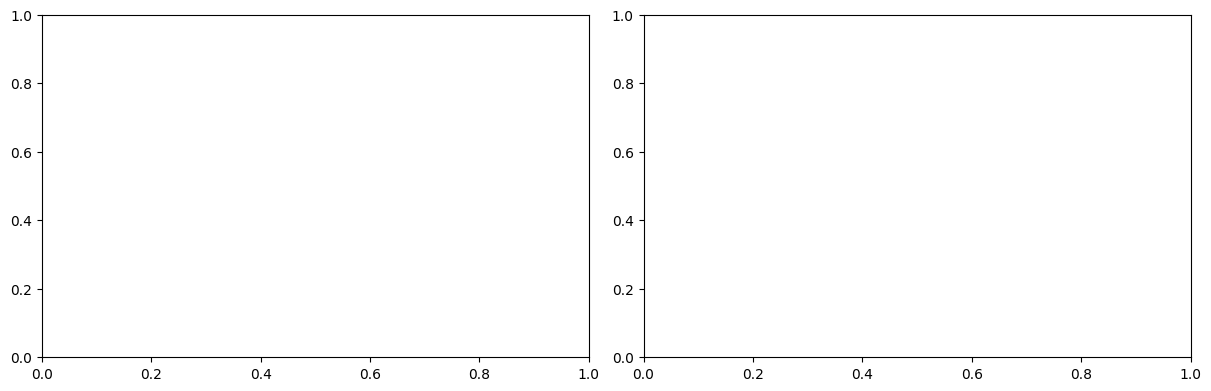

In [5]:
for ax, case, title in [
    (axes[1, 0], layered, "Estratificado · beta de referencia"),
    (axes[1, 1], strong, "Estratificado · beta mayor"),
    (axes[1, 2], challenge, "Control negativo salino cycle-skipping"),
]:
    model = np.asarray(case["methods"][METHOD]['model'])
    im = ax.imshow(
        model,
        origin="upper",
        aspect="auto",
        extent=[0, model.shape[1] * case['grid']["spacing"][1], model.shape[0] * case['grid']["spacing"][0], 0],
        cmap="viridis",
    )
    ax.set(title=title, xlabel="Distancia (m)", ylabel="Profundidad (m)")
    fig.colorbar(im, ax=ax, label="Velocidad (m/s)")
plt.show()
# El receptor 12 se excluye del ajuste porque 12 módulo 5 es igual a 2.
shot, receiver = 0, 12
assert receiver % 5 == 2
time_s = np.arange(len(layered["observed"][shot][receiver])) * layered["dt"]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), constrained_layout=True)


### El receptor 12 se selecciona mediante la regla registrada de retención módulo cinco. Comparar las formas de onda observada y predicha revela desajustes de fase y tiempo que un objetivo escalar puede ocultar; el residual sombreado es diagnóstico, no un conjunto de validación independiente. Como estos registros de fuente común son sintéticos y guardados, el gráfico no establece desempeño FWI en campo ni reproducibilidad del solver actual.

In [6]:
# Compara una recuperación estratificada con el desafío cycle-skip definido aparte.
for a, case, title in [
    (ax[0], layered, "Recuperación estratificada"),
    (ax[1], challenge, "Desafío cycle-skipping"),
]:
    observed = np.asarray(case["observed"])[shot, receiver]
    predicted = np.asarray(case["methods"][METHOD]["predicted"])[shot, receiver]
    a.plot(time_s, observed, color="#202d34", lw=1, label="observación sintética")
    a.plot(time_s, predicted, color="#d36c3b", lw=1, label="predicción")
    a.fill_between(time_s, observed - predicted, 0, color="#7189a0", alpha=0.22, label="residual")
    a.set(title=title, xlabel="Tiempo (s)", ylabel="Amplitud de presión")
    a.grid(alpha=0.2)
    a.legend(fontsize=8)
plt.show()
print("El receptor 12 se excluyó del ajuste; el residual es solo diagnóstico.")
print("Veredicto de salto de ciclo conservado:", challenge["methods"][METHOD]["evaluation"])


El receptor 12 se excluyó del ajuste; el residual es solo diagnóstico.
Veredicto de salto de ciclo conservado: {'status': 'negative-control', 'reason_codes': ['salt_cycle_skipping_challenge'], 'criterion': 'whole-model and active/withheld waveform improve the independent start; active/withheld WRMS <= 2', 'scope': 'synthetic baseline improvement and declared-noise consistency, not exact geology or field validation', 'optimizer_status': 'finite_budget'}


### Inicio independiente

Esta celda ejecuta una operación pública del flujo sobre las entradas declaradas.   


In [7]:
# Ejecute el método nombrado del pipeline con la entrada declarada en la lección.
from pathlib import Path
import sys

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data-pipeline").is_dir())
sys.path.insert(0, str(root / "data-pipeline"))
import torch, seismic

model_shape = np.asarray(layered["methods"][METHOD]['model']).T.shape
start_model = seismic.independent_start(model_shape)
print("forma inicial y rango en m/s", start_model.shape, float(start_model.min()), float(start_model.max()))


forma inicial y rango en m/s (128, 96) 1800.0 2845.0


### Método pasa-bajos

Esta celda ejecuta una operación pública del flujo sobre las entradas declaradas.   


In [8]:
# Ejecute el método nombrado del pipeline con la entrada declarada en la lección.
from pathlib import Path
import sys

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data-pipeline").is_dir())
sys.path.insert(0, str(root / "data-pipeline"))
obs_tensor = torch.as_tensor(np.asarray(layered["observed"]), dtype=torch.float32)
filtered_tensor = seismic.lowpass(obs_tensor, 5.0, dt=float(layered["dt"]))
print("energía relativa filtrada", float(filtered_tensor.square().mean() / obs_tensor.square().mean()))


energía relativa filtrada 0.17749862372875214


### Rugosidad física

Esta celda ejecuta una operación pública del flujo sobre las entradas declaradas.   


In [9]:
# Ejecute el método nombrado del pipeline con la entrada declarada en la lección.
from pathlib import Path
import sys

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data-pipeline").is_dir())
sys.path.insert(0, str(root / "data-pipeline"))
state_tensor = torch.as_tensor(np.asarray(layered["methods"][METHOD]['model']), dtype=torch.float32)
roughness_value = seismic.physical_roughness(state_tensor)
print("rugosidad escalada", float(roughness_value))


rugosidad escalada 0.09156230837106705


### Reglas de recuperación

Esta celda ejecuta una operación pública del flujo sobre las entradas declaradas.   


In [10]:
# Ejecute el método nombrado del pipeline con la entrada declarada en la lección.
from pathlib import Path
import sys

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data-pipeline").is_dir())
sys.path.insert(0, str(root / "data-pipeline"))
verdict = seismic.recovery_evaluation(layered["methods"][METHOD]["metrics"])
print("veredicto reproducido", verdict["status"], verdict["reason_codes"])


veredicto reproducido recovered []


### Control negativo de salto de ciclo

Esta celda ejecuta una operación pública del flujo sobre las entradas declaradas.   


In [11]:
# Ejecute el método nombrado del pipeline con la entrada declarada en la lección.
from pathlib import Path
import sys

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data-pipeline").is_dir())
sys.path.insert(0, str(root / "data-pipeline"))
challenge_verdict = seismic.recovery_evaluation(challenge["methods"][METHOD]["metrics"], challenge=True)
print("control negativo", challenge_verdict["status"], challenge_verdict["reason_codes"])


control negativo negative-control ['salt_cycle_skipping_challenge']




## Resultados

**Respuesta:** En el estado FWI guardado 80, el MSE relativo activo y retenido es 0.001149 y 0.001612. El salto de ciclo salino sigue como control negativo. Son estados reproducidos; el notebook no ejecutó una inversión nueva.

## Resumen

Los casos estratificados conservan sus actualizaciones y la falla del control desafiante en vez de mostrar solo una imagen favorable. Una solución nueva, validación con adquisición independiente y datos de campo quedan fuera de esta reproducción.

## Referencias

- [Ejemplo FWI acústica Deepwave](https://www.ausargeo.com/deepwave/example_fwi)
- Solver, objetivo, historial y evaluación: data-pipeline/seismic.py
- Artefactos sintéticos: data/derived/v2/FWI_LAYERED/ y data/derived/v2/FWI_CYCLE_SKIP/

**Respuesta:** En el estado guardado 80, los MSE relativos de entrenamiento y retención son 0,001149 y 0,001612. El caso de salto de ciclo salino permanece como control negativo. Son estados reproducidos; este notebook no ejecutó otra inversión.
